# 03 – Backtesting: is the winner real or lucky?

Notebook 02 scored the baselines on **one** 16-day period, and the 14-day mean won.
But the error chart showed the weekday rules winning on weekends, so the result could depend on
which two weeks we happened to pick.

One test period is like one fold of cross-validation: too little to trust a ranking.
The time series version of cross-validation is called **backtesting**:

1. Pretend it is an earlier date (the **cutoff**).
2. Forecast the next 16 days using only data up to the cutoff.
3. Score against what really happened.
4. Move the cutoff and repeat.

**Plan:**
1. Make the rules and the backtest reusable (`src/baselines.py`, `src/validation.py`).
2. Add one new rule that combines the two winners of notebook 02.
3. Backtest on 8 periods and read the results carefully.
4. Check the same season one year earlier, since the Kaggle test is 16–31 August.
5. Make our first Kaggle submission with the winner.

In [1]:
import sys
sys.path.append("..")

from functools import partial

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.baselines import last_day, level_and_weekday, mean_last, weekday_mean
from src.data import load_test, load_train
from src.metrics import rmsle
from src.validation import HORIZON, backtest, make_cutoffs, split

IMAGES = "../images"

train = load_train()
wide = train.pivot_table(index="date", columns=["store_nbr", "family"], values="sales", observed=True)

## 1. From notebook code to reusable functions

In notebook 02 the baselines were written inline, using variables like `actual` from the notebook.
To run them on many periods (and later on the Kaggle test), each rule is now a function in
`src/baselines.py` with **the same signature**:

```python
forecast = rule(history, dates)
```

`history` holds only what was known at the cutoff; `dates` are the days to forecast.
Because every rule looks the same, `backtest()` in `src/validation.py` can run any of them,
including models we build later.

Rules with settings (like "how many weeks") are fixed with `functools.partial`, which makes
a new function with some arguments already filled in.

In [2]:
rules = {
    "Last day": last_day,
    "Same weekday last week": partial(weekday_mean, weeks=1),
    "Mean of last 14 days": partial(mean_last, days=14),
    "Mean of last 4 same weekdays": partial(weekday_mean, weeks=4),
    "Level + weekday": level_and_weekday,
}

### The new rule: level + weekday

Notebook 02 left us with two half-good ideas:
- the **14-day mean** is smooth (little noise) but ignores weekends;
- the **weekday mean** catches weekends but is noisy (only 4 values per weekday).

`level_and_weekday` combines them (read its docstring in `src/baselines.py`):
- **level** = the average of the last 14 days → smooth;
- **weekday profile** = how far each weekday is above or below average, from the last 8 weeks → catches weekends,
  and uses 8 values per weekday instead of 4, so it is less noisy;
- **forecast = level + profile of that weekday.**

Everything is done on the **log scale**, `log1p(sales)`, the same scale RMSLE uses.
There, "Saturday sells 50% more" becomes "add a fixed amount", and averaging gives exactly the
number with the smallest RMSLE.

*Note:* the settings 14 days and 8 weeks were chosen before looking at the results, on purpose.
If we tried many settings and kept the best, the backtest score would be optimistic:
we would have tuned the rule to these particular weeks (the same reason we don't tune on the test set).

**First, a safety check.** Before trusting new code, check that it reproduces a known result.
The newest backtest window is exactly notebook 02's validation period, so the scores must match.

In [3]:
newest = make_cutoffs(wide.index.max(), n_windows=1)
backtest(wide, rules, newest).round(4)

,Last day,Same weekday last week,Mean of last 14 days,Mean of last 4 same weekdays,Level + weekday
window starts,,,,,
2017-07-31,0.6595,0.617,0.5191,0.5311,0.5244


Same numbers as notebook 02 (0.6595, 0.6170, 0.5191, 0.5311). The refactored code behaves like the original.
The new rule scores 0.5244 here, between the two rules it combines.

## 2. Backtest on 8 windows

`make_cutoffs` creates 8 back-to-back 16-day windows ending on the last day of train:
about four months, mid-April to mid-August 2017. For each window, the rules see only the data before it.

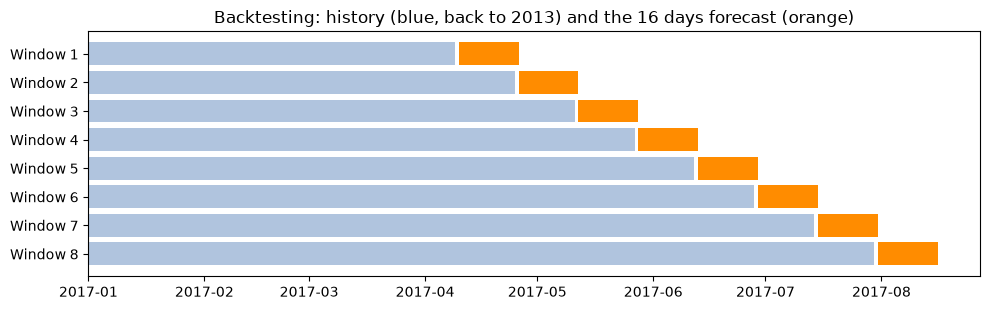

In [4]:
cutoffs = make_cutoffs(wide.index.max(), n_windows=8)

# A picture of what backtesting does: each row is one experiment.
fig, ax = plt.subplots(figsize=(10, 3.2))
start = pd.Timestamp("2017-01-01")
for i, cutoff in enumerate(cutoffs):
    ax.barh(i, (cutoff - start).days, left=start, color="lightsteelblue")
    ax.barh(i, HORIZON, left=cutoff + pd.Timedelta(days=1), color="darkorange")
ax.set_yticks(range(len(cutoffs)), [f"Window {i + 1}" for i in range(len(cutoffs))])
ax.invert_yaxis()
ax.set_title("Backtesting: history (blue, back to 2013) and the 16 days forecast (orange)")
fig.tight_layout()
fig.savefig(f"{IMAGES}/backtest_windows.png", dpi=120)
plt.show()

In [5]:
scores = backtest(wide, rules, cutoffs)
scores.round(3)

,Last day,Same weekday last week,Mean of last 14 days,Mean of last 4 same weekdays,Level + weekday
window starts,,,,,
2017-04-10,0.776,0.708,0.636,0.618,0.626
2017-04-26,0.621,0.622,0.495,0.570,0.596
2017-05-12,0.639,0.565,0.536,0.521,0.485
2017-05-28,0.618,0.530,0.486,0.495,0.422
2017-06-13,0.586,0.523,0.477,0.445,0.414
2017-06-29,0.605,0.518,0.461,0.425,0.406
2017-07-15,0.588,0.521,0.474,0.443,0.420
2017-07-31,0.659,0.617,0.519,0.531,0.524


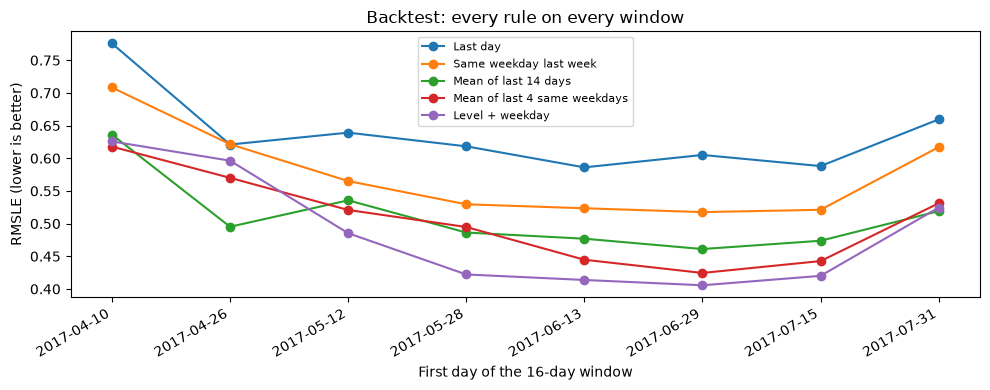

In [6]:
fig, ax = plt.subplots(figsize=(10, 4))
for name in scores.columns:
    ax.plot(scores.index, scores[name], marker="o", label=name)
ax.set_ylabel("RMSLE (lower is better)")
ax.set_xlabel("First day of the 16-day window")
ax.set_title("Backtest: every rule on every window")
ax.legend(fontsize=8)
plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
fig.tight_layout()
fig.savefig(f"{IMAGES}/backtest_scores.png", dpi=120)
plt.show()

## 3. Reading the results

Three ways to summarise the table, each answering a different question:

In [7]:
summary = pd.DataFrame({
    "mean RMSLE": scores.mean(),                            # how good on average?
    "std": scores.std(),                                    # how much does it vary between windows?
    "windows won": (scores.rank(axis=1) == 1).sum(),        # how often is it the best?
}).sort_values("mean RMSLE")
summary.round(3)

,mean RMSLE,std,windows won
Level + weekday,0.487,0.087,5
Mean of last 4 same weekdays,0.506,0.068,1
Mean of last 14 days,0.511,0.056,2
Same weekday last week,0.575,0.068,0
Last day,0.637,0.061,0


**What we found:**
- **Level + weekday has the best average and wins 5 of the 8 windows.** Combining the two ideas helped.
- **The newest window (notebook 02's period) was unusual:** it is one of the few where the plain 14-day mean wins.
  Picking a rule from that window alone would have picked the wrong one.
- **The windows differ more than the rules do.** Look at the chart: every line moves up and down together.
  The April windows are hard for every rule (the first one contains Easter week, 16 April 2017, which may explain part of it),
  June is easy for all of them. The standard deviation between windows (about 0.06–0.09) is larger than the
  gap between the top rules.

That last point decides **how to compare rules**: not by their averages alone, but **window by window**.
Within one window, both rules face the same conditions, so the difference between them is a fair comparison.
(The same idea as the fold-by-fold check in the credit risk project.)

In [8]:
diff = scores["Level + weekday"] - scores["Mean of last 14 days"]
print("Level + weekday minus 14-day mean, per window (negative = new rule better):")
print(diff.round(3).to_string())
print(f"\nBetter in {(diff < 0).sum()} of {len(diff)} windows, by {-diff.mean():.3f} on average")

Level + weekday minus 14-day mean, per window (negative = new rule better):
window starts
2017-04-10   -0.010
2017-04-26    0.101
2017-05-12   -0.050
2017-05-28   -0.064
2017-06-13   -0.063
2017-06-29   -0.055
2017-07-15   -0.054
2017-07-31    0.005

Better in 6 of 8 windows, by 0.024 on average


Level + weekday beats the 14-day mean in 6 of 8 windows, usually by a clear margin.
The two windows it loses are the late-April one and the newest one: it is not better everywhere, but it is the
best bet. Rule of thumb: trust a new method when it wins **consistently**, not just on average.

## 4. The same season one year earlier

The Kaggle test is **16–31 August 2017**. Our 8 windows cover April–August 2017, but none of them is late August.
Seasons can matter, so let's also backtest the same dates in 2016.

In [9]:
same_season_2016 = [pd.Timestamp("2016-08-15")]  # cutoff: forecast 16–31 August 2016
backtest(wide, rules, same_season_2016).round(3)

,Last day,Same weekday last week,Mean of last 14 days,Mean of last 4 same weekdays,Level + weekday
window starts,,,,,
2016-08-16,0.699,0.856,0.838,0.83,0.787


Every rule does far worse than in 2017 (0.70–0.86, against 0.41–0.78 across the 2017 windows). Before drawing conclusions,
**look at what went wrong**. Which series contribute most of the error?

In [10]:
history, actual = split(wide, pd.Timestamp("2016-08-15"))
forecast = level_and_weekday(history, actual.index)

# Squared log error for every (day, series), summed per store: which stores cause the error?
squared_errors = (np.log1p(forecast) - np.log1p(actual)) ** 2
by_store = squared_errors.sum().groupby(level="store_nbr", observed=True).sum()
(by_store / by_store.sum()).sort_values(ascending=False).head(5).round(2)

store_nbr
18    0.41
25    0.31
10    0.01
13    0.01
20    0.01
dtype: float64

In [11]:
# Two stores cause most of the error. What did they sell around that time?
store_totals = train.groupby(["date", "store_nbr"], observed=True)["sales"].sum().unstack()
store_totals.loc["2016-08-10":"2016-08-31", [18, 25]].T.round(0)

date,2016-08-10,2016-08-11,2016-08-12,2016-08-13,2016-08-14,2016-08-15,2016-08-16,2016-08-17,2016-08-18,2016-08-19,...,2016-08-22,2016-08-23,2016-08-24,2016-08-25,2016-08-26,2016-08-27,2016-08-28,2016-08-29,2016-08-30,2016-08-31
store_nbr,,,,,,,,,,,,,,,,,,,,,
18,6604.0,7989.0,7256.0,7271.0,8085.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
25,9308.0,11377.0,21941.0,15623.0,7681.0,7986.0,6576.0,7418.0,5668.0,8461.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


**What happened:** store 18 closed on 15 August 2016 (for about 3.5 months), and store 25 closed on 22 August
(for about 2 months). Every rule kept forecasting normal sales; the truth was zero. With the RMSLE, forecasting
hundreds when the truth is 0 is a huge error, and these two stores alone dominate the score.

In [12]:
without_closed = ~actual.columns.get_level_values("store_nbr").isin([18, 25])
pd.Series({
    name: rmsle(actual.loc[:, without_closed], rule(history, actual.index).loc[:, without_closed])
    for name, rule in rules.items()
}, name="RMSLE without stores 18 and 25").round(3)

Last day                        0.562
Same weekday last week          0.537
Mean of last 14 days            0.461
Mean of last 4 same weekdays    0.455
Level + weekday                 0.424
Name: RMSLE without stores 18 and 25, dtype: float64

Without the two closed stores, August 2016 looks like a normal window, and **level + weekday is again the best rule**.

Lessons:
- **Always look at your worst window.** A bad average can come from one event, not from a bad method.
- No rule based on past sales can foresee a store closing. Before submitting, it's worth checking
  that no store is closed at the end of our data. (None is: every store has sales in the last weeks of train.)
- Don't silently drop awkward windows from a backtest. Here we keep the 8-window result as our main number,
  and use 2016 only to check the season.

### A seasonal warning: back to school

There is one more thing about late August. Let's use the same error breakdown as above, by product family,
on the newest window (31 July – 15 August 2017):

In [13]:
history, actual = split(wide, cutoffs[-1])
squared_errors = (np.log1p(level_and_weekday(history, actual.index)) - np.log1p(actual)) ** 2
by_family = squared_errors.sum().groupby(level="family", observed=True).sum()
(by_family / by_family.sum()).sort_values(ascending=False).head(5).round(2)

family
SCHOOL AND OFFICE SUPPLIES    0.37
LINGERIE                      0.06
GROCERY II                    0.06
BEAUTY                        0.04
CELEBRATION                   0.04
dtype: float64

One family out of 33 causes over a third of the error. Let's look at it across years:

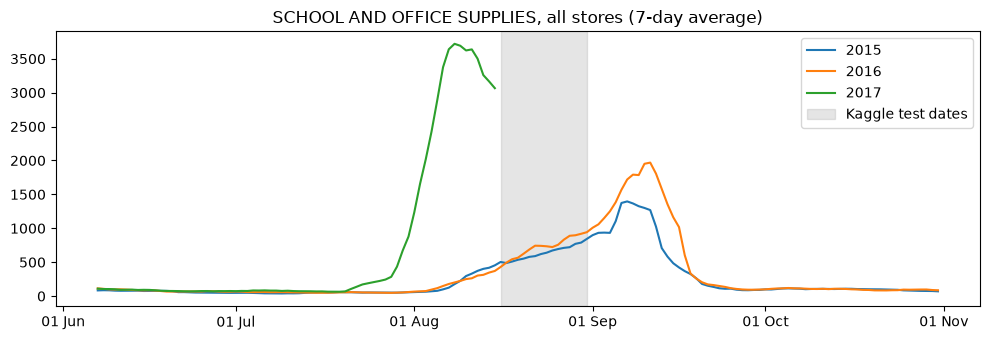

In [14]:
school = train[train["family"] == "SCHOOL AND OFFICE SUPPLIES"].groupby("date")["sales"].sum()

fig, ax = plt.subplots(figsize=(10, 3.5))
for year in [2015, 2016, 2017]:
    part = school[f"{year}-06-01":f"{year}-10-31"]
    # Plot all years on one shared calendar (Jun–Oct) by replacing the year
    ax.plot(part.index.map(lambda d: d.replace(year=2000)), part.rolling(7).mean(), label=str(year))
ax.axvspan(pd.Timestamp("2000-08-16"), pd.Timestamp("2000-08-31"), color="grey", alpha=0.2, label="Kaggle test dates")
ax.set_title("SCHOOL AND OFFICE SUPPLIES, all stores (7-day average)")
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%d %b"))
ax.legend()
fig.tight_layout()
fig.savefig(f"{IMAGES}/back_to_school.png", dpi=120)
plt.show()

**Back-to-school shopping.** In 2015 and 2016, school supplies started rising around the start of August and peaked in
early-to-mid September at about 25 times their June level.

**In 2017 the season came about a month earlier, and higher:** it peaked around 8 August at over 40 times
the June level, and it was already falling when train ends. The Kaggle test dates (grey) come right after that peak.

What this means:
- Our rules assume the next 16 days look like the last 14. For this family, if the decline continues,
  they will forecast too high.
- "Same time last year" would be misleading too: in 2016, sales were still rising during these dates.
- **Seasonal patterns don't always fall on the same dates every year.** Recent data can tell us more than
  last year's calendar. Something to remember when we build features.

## 5. First Kaggle submission

The rule that won the backtest is **level + weekday**. To forecast the real test period, we call the very same
function, now with **all** of train as the history and the 16 test dates as `dates`.

In [15]:
test = load_test()
# name="date" so that, after reshaping below, the dates land in a column called "date", ready to merge with test.
test_dates = pd.DatetimeIndex(sorted(test["date"].unique()), name="date")
forecast = level_and_weekday(wide, test_dates)

# Wide -> long: one row per (store, family, date), the layout of test.csv.
# unstack() turns the columns into index levels; reset_index turns them into ordinary columns.
long = forecast.unstack().rename("sales").reset_index()

# Match each test row (which has an id) with its forecast.
submission = test.merge(long, on=["store_nbr", "family", "date"], how="left")[["id", "sales"]]

# Checks before saving: one forecast per test row, nothing missing, nothing negative.
assert len(submission) == len(test)
assert submission["sales"].notna().all()
assert (submission["sales"] >= 0).all()

submission.to_csv("../submissions/v1_level_weekday.csv", index=False)
submission.head()

,id,sales
0,3000888,3.288932
1,3002670,3.945445
2,3004452,6.105015
3,3006234,6.669071
4,3008016,2.066895


The file is in `submissions/`. To score it, upload it on the competition's **Submit Prediction** page.
The backtest suggests an RMSLE around 0.49, but expect the leaderboard to differ: the test period comes right
after the back-to-school peak, a situation none of our 8 windows contains. Comparing the two numbers is itself a lesson about
how well a backtest predicts the future.

## Summary

| Finding | Consequence |
|---|---|
| One window picked the wrong winner | Always backtest on several windows |
| Windows differ more than rules do | Compare rules window by window, not only by averages |
| **Level + weekday** wins 6 of 8 windows against the 14-day mean, average **RMSLE ≈ 0.487** | The new bar to beat |
| Two store closures wrecked the August 2016 window | Look at the worst window before concluding anything |
| Back-to-school came a month early in 2017 and peaks just before the test | Seasons can shift: recent data can beat "same time last year" |

**Next step (step 5):** calendar features. We stop hand-writing rules and start preparing data for a model:
day of week, month, paydays, holidays.